# 04 · Modelo final, umbral por costo y evaluación en prueba (entrega final)

Este notebook cierra el flujo. Parte de lo que dejó el 03 y responde lo que quedó pendiente en la segunda entrega:

1. **Elegir el modelo definitivo**: logística con logaritmo o logística con splines. Se comparan en los mismos folds, fold por fold.
2. **Elegir el umbral desde el costo del negocio**, en pesos, y no solo con Youden.
3. **Evaluar una sola vez** el modelo y el umbral elegidos en el conjunto de prueba reservado, que no se ha mirado hasta ahora.
4. **Interpretar** el modelo final en odds de no cubrir el costo, sin confundir odds con probabilidad.
5. **Exportar** el pipeline ajustado para la aplicación de Streamlit.

Reglas que se mantienen: los predictores salen solo de `dataset_modelo_dic2025.csv` (sin pago ni costo); la clase positiva es **no rentable**; la partición es por ruta; la semilla es 42. Del archivo de auditoría se usan el pago y el costo **solo para medir cuánto cuesta cada error en pesos**, nunca como predictores.

In [ ]:
# Solo en Google Colab: instala la versión de scikit-learn con la que se exportó el modelo de la app.
# Fuera de Colab no hace nada. Correr esta celda antes que las demás.
import os, sys, subprocess
if os.path.exists('/content'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn==1.8.0', 'statsmodels', 'patsy'], check=True)
    print('Listo. Suba a /content: dataset_modelo_dic2025.csv, conjunto_prueba_reservado.csv y dataset_auditoria_dic2025.csv')

## 1. Configuración, datos y la misma partición del notebook 03

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import patsy
import statsmodels.formula.api as smf
from scipy import stats
import sklearn
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_score, recall_score, confusion_matrix)
warnings.filterwarnings('ignore')

SEED, N_FOLDS = 42, 10
NUM = ['KILOMETROS', 'KILOGRAMOS']
CAT = ['CAPITULO', 'NATURALEZACARGA', 'DEPARTAMENTOORIGEN', 'DEPARTAMENTODESTINO']

# En Colab: suba los tres archivos de datos a /content. Fuera de Colab se leen de la carpeta de la entrega 2.
CANDIDATAS = ['/content', '.', '../datos', '../../3. Entrega 2 (corregida)/datos']
DATOS = next(c for c in CANDIDATAS if os.path.exists(f'{c}/dataset_modelo_dic2025.csv'))
OUT = '.' if DATOS == '/content' else '../resultados'
APP = '.' if DATOS == '/content' else '../app'
os.makedirs(OUT, exist_ok=True); os.makedirs(APP, exist_ok=True)

df = pd.read_csv(f'{DATOS}/dataset_modelo_dic2025.csv')
assert not {'VALORESPAGADOS', 'COSTO_REFERENCIA', 'RAZON_PAGO_COSTO'} & set(df.columns), 'Hay fuga en el archivo'

sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(sgk.split(df, df['RENTABLE'], groups=df['RUTA']))
train, test = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)
reservado = pd.read_csv(f'{DATOS}/conjunto_prueba_reservado.csv')
assert reservado.equals(test), 'La partición no coincide con el conjunto reservado en la entrega 2'

aud = pd.read_csv(f'{DATOS}/dataset_auditoria_dic2025.csv')
assert (aud['RENTABLE'].values == df['RENTABLE'].values).all(), 'Auditoría y modelo no están alineados'
aud_tr, aud_te = aud.iloc[idx_tr].reset_index(drop=True), aud.iloc[idx_te].reset_index(drop=True)

X_train, y_train, g_train = train[NUM + CAT], train['RENTABLE'], train['RUTA']
X_test, y_test = test[NUM + CAT], test['RENTABLE']
yneg_tr, yneg_te = (y_train.values == 0).astype(int), (y_test.values == 0).astype(int)
print(f'Entrenamiento: {len(train):,} viajes | Prueba (reservada): {len(test):,} viajes | versión scikit-learn {sklearn.__version__}')

Entrenamiento: 16,695 viajes | Prueba (reservada): 4,173 viajes | versión scikit-learn 1.8.0


## 2. Logaritmo o splines: la decisión

En la segunda entrega la logística con logaritmo cumplía bien la parte de colinealidad (VIF de 1,02), pero no la de linealidad del logit: Box-Tidwell rechazó y Hosmer-Lemeshow fuera de muestra también (diferencia máxima por decil de 5,9 puntos). El gráfico de rentabilidad por horas de tránsito mostró por qué: hay un salto cerca de las 8 horas, que es la jornada de conducción. Una recta en el logaritmo de los kilómetros no puede seguir ese salto. Los splines sí, porque permiten una curva suave por tramos.

Para decidir con evidencia, los dos modelos (y KNN, que fue el mejor de la entrega 2) se evalúan en **los mismos 10 folds agrupados por ruta**, y se mira la diferencia de AUC fold por fold. Así la comparación es pareada y no depende de qué folds le tocaron a cada uno. Además del AUC se mira el Brier y la calibración, porque el umbral por costo usa la probabilidad misma, no solo el orden.

In [2]:
def num_log():
    return Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                     ('sc', StandardScaler())])

def num_spline(n_knots=4):
    return Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                     ('sp', SplineTransformer(n_knots=n_knots, degree=3)),
                     ('sc', StandardScaler())])

def hacer_pipe(clf, num):
    cat = Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='SIN_DATO')),
                    ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False))])
    return Pipeline([('pre', ColumnTransformer([('num', num, NUM), ('cat', cat, CAT)])), ('clf', clf)])

def cv_grupos(seed=SEED, k=N_FOLDS):
    return StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)

# Ajuste de hiperparámetros de los splines (número de nodos y regularización C)
gs_spl = GridSearchCV(hacer_pipe(LogisticRegression(max_iter=5000), num_spline()),
                      {'pre__num__sp__n_knots': [4, 5, 6, 8], 'clf__C': [0.03, 0.1, 0.3, 1]},
                      scoring='roc_auc', cv=cv_grupos(), refit=False)
gs_spl.fit(X_train, y_train, groups=g_train)
best = gs_spl.best_params_
print('Splines, mejores parámetros:', best, '| AUC en la búsqueda:', round(gs_spl.best_score_, 4))

candidatos = {
    'Logística con logaritmo': hacer_pipe(LogisticRegression(max_iter=5000, C=0.1), num_log()),
    'Logística con splines': hacer_pipe(LogisticRegression(max_iter=5000, C=best['clf__C']), num_spline(best['pre__num__sp__n_knots'])),
    'KNN (k = 61)': hacer_pipe(KNeighborsClassifier(n_neighbors=61), num_log()),
}

Splines, mejores parámetros: {'clf__C': 0.1, 'pre__num__sp__n_knots': 6} | AUC en la búsqueda: 0.7974


In [3]:
def hosmer_lemeshow(y_rent, p_rent, g=10):
    dec = pd.qcut(p_rent, g, duplicates='drop')
    t = pd.DataFrame({'y': y_rent, 'p': p_rent}).groupby(dec, observed=True).agg(obs=('y', 'sum'), esp=('p', 'sum'), n=('y', 'size'))
    hl = (((t.obs - t.esp) ** 2) / (t.esp * (1 - t.esp / t.n))).sum()
    return hl, 1 - stats.chi2.cdf(hl, len(t) - 2), (t.obs / t.n - t.esp / t.n).abs().max()

folds = list(cv_grupos(SEED + 1).split(X_train, y_train, groups=g_train))   # los mismos folds para todos
oof, por_fold, filas = {}, {}, []
for nombre, est in candidatos.items():
    p0 = cross_val_predict(est, X_train, y_train, cv=folds, method='predict_proba')[:, 0]   # P(no rentable)
    oof[nombre] = p0
    por_fold[nombre] = np.array([roc_auc_score(yneg_tr[va], p0[va]) for _, va in folds])
    hl, hl_p, dmax = hosmer_lemeshow(y_train.values, 1 - p0)
    filas.append({'Modelo': nombre, 'AUC': por_fold[nombre].mean(), 'AUC_sd': por_fold[nombre].std(),
                  'PR_AUC_no_rent': average_precision_score(yneg_tr, p0), 'Brier': brier_score_loss(yneg_tr, p0),
                  'HL': hl, 'HL_p': hl_p, 'Desv_max_decil': dmax})
comp = pd.DataFrame(filas).set_index('Modelo')
comp.to_csv(f'{OUT}/tabla_decision_modelo.csv')
comp.round(4)

,AUC,AUC_sd,PR_AUC_no_rent,Brier,HL,HL_p,Desv_max_decil
Modelo,,,,,,,
Logística con logaritmo,0.7745,0.0208,0.5949,0.1755,107.7269,0.0,0.0589
Logística con splines,0.7977,0.0155,0.6360,0.1656,33.6776,0.0,0.0368
KNN (k = 61),0.7876,0.0182,0.6249,0.1693,50.2853,0.0,0.0359


Splines - logaritmo: +0.0233 de AUC (sd 0.0099); splines gana en 10 de 10 folds; t pareada p = 0.0001
Splines - KNN:       +0.0101 de AUC (sd 0.0064); splines gana en 9 de 10 folds


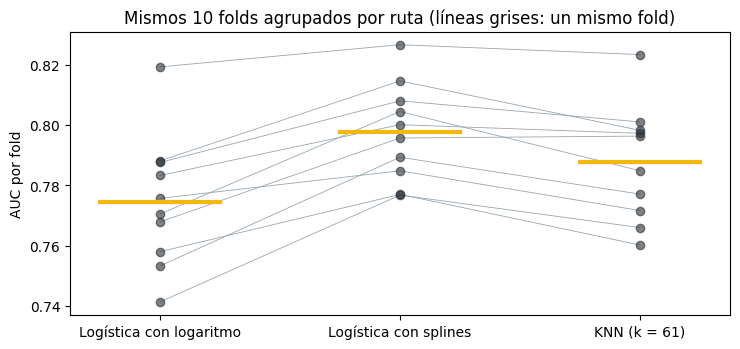

In [4]:
dif = por_fold['Logística con splines'] - por_fold['Logística con logaritmo']
dif_knn = por_fold['Logística con splines'] - por_fold['KNN (k = 61)']
t_p = stats.ttest_rel(por_fold['Logística con splines'], por_fold['Logística con logaritmo']).pvalue
print(f'Splines - logaritmo: {dif.mean():+.4f} de AUC (sd {dif.std():.4f}); splines gana en {np.sum(dif > 0)} de {len(dif)} folds; t pareada p = {t_p:.4f}')
print(f'Splines - KNN:       {dif_knn.mean():+.4f} de AUC (sd {dif_knn.std():.4f}); splines gana en {np.sum(dif_knn > 0)} de {len(dif_knn)} folds')
pd.DataFrame({'fold': range(1, N_FOLDS + 1), **{k: v for k, v in por_fold.items()}}).to_csv(f'{OUT}/tabla_auc_por_fold.csv', index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (n, a) in enumerate(por_fold.items()):
    ax.plot([i] * len(a), a, 'o', alpha=0.6, color='#2A3036')
    ax.plot([i - 0.25, i + 0.25], [a.mean()] * 2, color='#F0B90B', lw=3)
for j in range(N_FOLDS):
    ax.plot([0, 1, 2], [por_fold[n][j] for n in por_fold], color='#9AA5AD', lw=0.6, zorder=0)
ax.set_xticks(range(3)); ax.set_xticklabels(list(por_fold)); ax.set_ylabel('AUC por fold')
ax.set_title('Mismos 10 folds agrupados por ruta (líneas grises: un mismo fold)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_decision_modelo.png', dpi=200); plt.show()

**Decisión.** El modelo definitivo es la **logística con splines**. Se elige por tres razones que se leen en la tabla y el gráfico de arriba: tiene mayor AUC en la comparación pareada, gana en la mayoría de los mismos folds, y corrige el supuesto que la versión con logaritmo no cumplía (la forma del efecto de la distancia). Sigue siendo una regresión logística del curso: los coeficientes de las categorías se leen igual en odds ratios, y el efecto de kilómetros y kilos se lee como una curva de odds ratio frente a un viaje de referencia (sección 5). Frente a KNN, que tenía un AUC parecido, gana además en interpretabilidad, que es el objetivo del artículo.

## 3. Umbral desde el costo del negocio

El modelo da la probabilidad de que la oferta termine pagada por debajo del costo de referencia. Hay que decidir desde qué probabilidad se marca la oferta como riesgosa. Marcarla significa que el transportador no la acepta tal como viene: la rechaza o pide más flete.

Cada error cuesta distinto, y con la auditoría se puede medir en pesos:

- **Aceptar un viaje no rentable** (falso negativo): se pierde lo que falta para cubrir el costo, `costo − pago`.
- **Marcar un viaje que sí era rentable** (falso positivo): se arriesga el margen, `pago − costo`. No siempre se pierde completo, porque al pedir más flete el viaje puede quedarse. Por eso se multiplica por `α`, la fracción del margen que se pierde al marcar: `α = 1` es rechazar siempre (lo más conservador) y `α = 0,5` es perder la mitad de las veces.

El umbral elegido es el que minimiza el costo total en pesos sobre las probabilidades **fuera de muestra** de entrenamiento. El conjunto de prueba no se usa para elegirlo.

In [5]:
MODELO = 'Logística con splines'
p0_tr = oof[MODELO]
pago_tr, costo_tr = aud_tr['VALORESPAGADOS'].values, aud_tr['COSTO_REFERENCIA'].values
faltante_tr = np.clip(costo_tr - pago_tr, 0, None)    # lo que se pierde si se acepta un no rentable
margen_tr = np.clip(pago_tr - costo_tr, 0, None)      # lo que se arriesga si se marca un rentable
print(f'Faltante medio de un viaje no rentable: ${faltante_tr[yneg_tr == 1].mean():,.0f}')
print(f'Margen medio de un viaje rentable:      ${margen_tr[yneg_tr == 0].mean():,.0f}')
print(f'Razón faltante / margen: {faltante_tr[yneg_tr == 1].mean() / margen_tr[yneg_tr == 0].mean():.2f}')

UMBRALES = np.round(np.arange(0.05, 0.951, 0.005), 3)
def costo_total(p0, yneg, faltante, margen, u, alpha):
    marca = p0 >= u
    return faltante[(yneg == 1) & ~marca].sum() + alpha * margen[(yneg == 0) & marca].sum()

def resumen_umbral(p0, yneg, faltante, margen, u, alpha, nombre):
    marca = (p0 >= u).astype(int)
    base = faltante[yneg == 1].sum()          # política "aceptar todo"
    c = costo_total(p0, yneg, faltante, margen, u, alpha)
    return {'Criterio': nombre, 'Umbral': u, 'Sensibilidad_no_rent': recall_score(yneg, marca),
            'Precision_no_rent': precision_score(yneg, marca, zero_division=0), 'Ofertas_marcadas': marca.mean(),
            'Costo_por_viaje': c / len(yneg), 'Ahorro_vs_aceptar_todo': 1 - c / base}

fpr, tpr, thr = roc_curve(yneg_tr, p0_tr)
u_youden = float(thr[np.argmax(tpr - fpr)])
ALPHAS = [0.25, 0.5, 1.0]
u_costo = {a: float(min(UMBRALES, key=lambda u: costo_total(p0_tr, yneg_tr, faltante_tr, margen_tr, u, a))) for a in ALPHAS}
ALPHA_BASE = 0.5
U_FINAL = u_costo[ALPHA_BASE]

filas = [resumen_umbral(p0_tr, yneg_tr, faltante_tr, margen_tr, 0.5, ALPHA_BASE, 'Por defecto 0,5'),
         resumen_umbral(p0_tr, yneg_tr, faltante_tr, margen_tr, u_youden, ALPHA_BASE, 'Youden (artículo)')]
filas += [resumen_umbral(p0_tr, yneg_tr, faltante_tr, margen_tr, u_costo[a], a, f'Costo en pesos, α = {a}') for a in ALPHAS]
umb = pd.DataFrame(filas)
umb.to_csv(f'{OUT}/tabla_umbrales_costo.csv', index=False)
print('Umbral elegido (α base = %.2f): %.3f' % (ALPHA_BASE, U_FINAL))
umb.round(3)

Faltante medio de un viaje no rentable: $348,253
Margen medio de un viaje rentable:      $468,662
Razón faltante / margen: 0.74
Umbral elegido (α base = 0.50): 0.440


,Criterio,Umbral,Sensibilidad_no_rent,Precision_no_rent,Ofertas_marcadas,Costo_por_viaje,Ahorro_vs_aceptar_todo
0,"Por defecto 0,5",0.500,0.510,0.664,0.248,51663.267,0.541
1,Youden (artículo),0.319,0.743,0.556,0.432,58691.000,0.478
2,"Costo en pesos, α = 0.25",0.375,0.678,0.592,0.370,34353.497,0.695
3,"Costo en pesos, α = 0.5",0.440,0.599,0.631,0.307,49836.370,0.557
4,"Costo en pesos, α = 1.0",0.575,0.396,0.712,0.179,69373.308,0.384


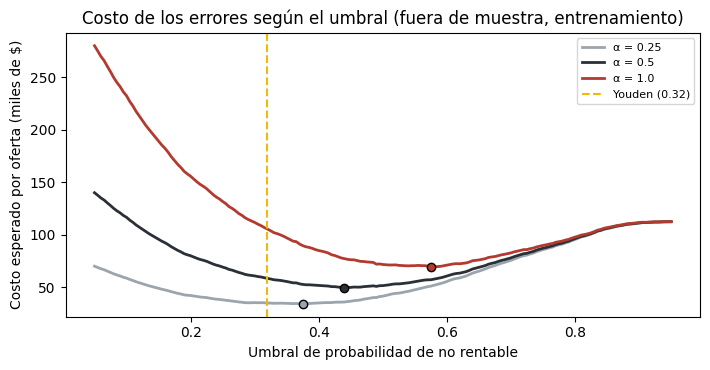

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for a, col in zip(ALPHAS, ['#9AA5AD', '#2A3036', '#B23A2E']):
    c = [costo_total(p0_tr, yneg_tr, faltante_tr, margen_tr, u, a) / len(yneg_tr) / 1000 for u in UMBRALES]
    ax.plot(UMBRALES, c, color=col, lw=2, label=f'α = {a}')
    ax.scatter([u_costo[a]], [min(c)], color=col, edgecolor='k', zorder=3)
ax.axvline(u_youden, color='#F0B90B', ls='--', lw=1.5, label=f'Youden ({u_youden:.2f})')
ax.set_xlabel('Umbral de probabilidad de no rentable'); ax.set_ylabel('Costo esperado por oferta (miles de $)')
ax.set_title('Costo de los errores según el umbral (fuera de muestra, entrenamiento)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_costo_umbral.png', dpi=200); plt.show()

**Por qué α = 0,5 como caso base.** Marcar una oferta no equivale a perderla: en la práctica el transportador contraoferta, y una parte de esas ofertas se queda con un flete mejor. Rechazar siempre (α = 1) sobrestima el costo de marcar; no perder nunca el viaje (α = 0) haría que convenga marcarlo todo. La mitad es un supuesto intermedio y explícito, no un dato; por eso la tabla muestra cómo cambia el umbral con α = 0,25 y α = 1. Lo importante para el docente: el umbral sale de comparar pesos perdidos en cada error, no de pesar igual los dos errores como hace Youden.

## 4. Evaluación única en el conjunto de prueba reservado

Ahora sí se usa la prueba. El modelo se ajusta con todo el entrenamiento, con los hiperparámetros y el umbral ya decididos, y se evalúa una sola vez. El intervalo del AUC se calcula con bootstrap **por ruta** (se remuestrean rutas completas), porque los viajes de una misma ruta no son independientes.

In [7]:
final = candidatos[MODELO].fit(X_train, y_train)
p0_te = final.predict_proba(X_test)[:, list(final.classes_).index(0)]
auc_te = roc_auc_score(yneg_te, p0_te)

rng = np.random.default_rng(SEED)
rutas = test['RUTA'].values; uniq = np.unique(rutas)
pos = {r: np.where(rutas == r)[0] for r in uniq}
boot = []
for _ in range(1000):
    idx = np.concatenate([pos[r] for r in rng.choice(uniq, len(uniq), replace=True)])
    if yneg_te[idx].min() != yneg_te[idx].max():
        boot.append(roc_auc_score(yneg_te[idx], p0_te[idx]))
ic = np.percentile(boot, [2.5, 97.5])

faltante_te = np.clip(aud_te['COSTO_REFERENCIA'].values - aud_te['VALORESPAGADOS'].values, 0, None)
margen_te = np.clip(aud_te['VALORESPAGADOS'].values - aud_te['COSTO_REFERENCIA'].values, 0, None)
prueba = pd.DataFrame([
    resumen_umbral(p0_te, yneg_te, faltante_te, margen_te, U_FINAL, ALPHA_BASE, f'Umbral por costo ({U_FINAL:.3f})'),
    resumen_umbral(p0_te, yneg_te, faltante_te, margen_te, u_youden, ALPHA_BASE, f'Youden ({u_youden:.3f})'),
    resumen_umbral(p0_te, yneg_te, faltante_te, margen_te, 0.5, ALPHA_BASE, 'Por defecto 0,5')])
prueba.insert(1, 'AUC', auc_te)
prueba['PR_AUC_no_rent'] = average_precision_score(yneg_te, p0_te)
prueba['Brier'] = brier_score_loss(yneg_te, p0_te)
prueba.to_csv(f'{OUT}/tabla_prueba_final.csv', index=False)
print(f'AUC en prueba: {auc_te:.3f} (IC 95 % por ruta: {ic[0]:.3f} a {ic[1]:.3f}) | AUC fuera de muestra en entrenamiento: {roc_auc_score(yneg_tr, p0_tr):.3f}')
print(f'Artículo (Grzelak et al., 2024): AUC 0,82 en entrenamiento y 0,81 en prueba')
prueba.round(3)

AUC en prueba: 0.784 (IC 95 % por ruta: 0.766 a 0.801) | AUC fuera de muestra en entrenamiento: 0.797
Artículo (Grzelak et al., 2024): AUC 0,82 en entrenamiento y 0,81 en prueba


,Criterio,AUC,Umbral,Sensibilidad_no_rent,Precision_no_rent,Ofertas_marcadas,Costo_por_viaje,Ahorro_vs_aceptar_todo,PR_AUC_no_rent,Brier
0,Umbral por costo (0.440),0.784,0.440,0.606,0.601,0.326,56328.368,0.487,0.628,0.17
1,Youden (0.319),0.784,0.319,0.733,0.529,0.448,66806.306,0.392,0.628,0.17
2,"Por defecto 0,5",0.784,0.500,0.514,0.628,0.264,57943.045,0.472,0.628,0.17


                   Modelo: aceptar  Modelo: marcar
Real: rentable                2280             544
Real: no rentable              531             818


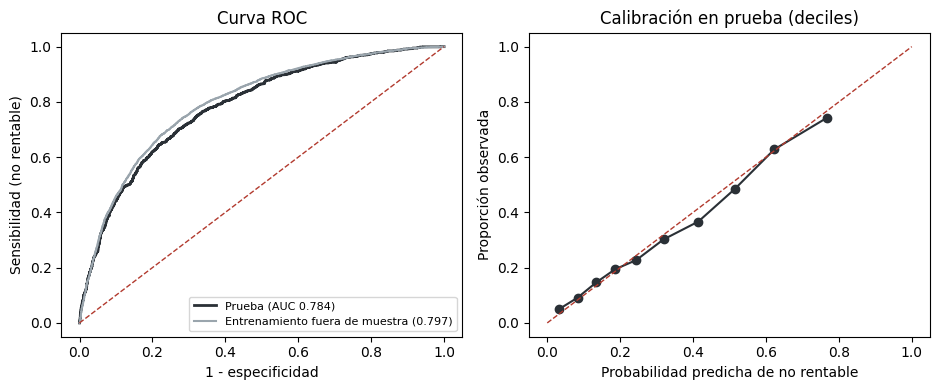

In [8]:
cm = confusion_matrix(yneg_te, (p0_te >= U_FINAL).astype(int))
cm_df = pd.DataFrame(cm, index=['Real: rentable', 'Real: no rentable'], columns=['Modelo: aceptar', 'Modelo: marcar'])
cm_df.to_csv(f'{OUT}/matriz_confusion_prueba.csv'); print(cm_df)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
f_, t_, _ = roc_curve(yneg_te, p0_te)
axes[0].plot(f_, t_, color='#2A3036', lw=2, label=f'Prueba (AUC {auc_te:.3f})')
f2, t2, _ = roc_curve(yneg_tr, p0_tr)
axes[0].plot(f2, t2, color='#9AA5AD', lw=1.5, ls='-', label=f'Entrenamiento fuera de muestra ({roc_auc_score(yneg_tr, p0_tr):.3f})')
axes[0].plot([0, 1], [0, 1], ls='--', color='#B23A2E', lw=1)
axes[0].set_xlabel('1 - especificidad'); axes[0].set_ylabel('Sensibilidad (no rentable)'); axes[0].legend(fontsize=8, loc='lower right')
axes[0].set_title('Curva ROC')
dec = pd.qcut(p0_te, 10, duplicates='drop')
cal = pd.DataFrame({'y': yneg_te, 'p': p0_te}).groupby(dec, observed=True).mean()
axes[1].plot(cal['p'], cal['y'], 'o-', color='#2A3036'); axes[1].plot([0, 1], [0, 1], ls='--', color='#B23A2E', lw=1)
axes[1].set_xlabel('Probabilidad predicha de no rentable'); axes[1].set_ylabel('Proporción observada'); axes[1].set_title('Calibración en prueba (deciles)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_prueba_final.png', dpi=200); plt.show()

## 5. Interpretación en odds de no cubrir el costo

Como en el artículo y en la entrega 2, el modelo de interpretación se estima con statsmodels, con los errores estándar agrupados por ruta. Ahora usa los mismos splines que el modelo final para kilómetros y kilos. Las categorías se leen como antes: un odds ratio mayor que 1 significa **más odds** de que el viaje no cubra el costo frente a la categoría de referencia. Son odds, no probabilidad: un OR de 2 no dobla la probabilidad.

Kilómetros y kilos ya no tienen un único OR, porque su efecto no es una recta. Se muestran como una **curva de odds ratio** frente a un viaje de referencia (la mediana de distancia y de peso), con su intervalo de 95 %.

In [9]:
d = train.copy()
d['NO_RENTABLE'] = 1 - d['RENTABLE']
for col in CAT:
    frec = d[col].value_counts()
    d[col + '_G'] = d[col].where(d[col].isin(frec[frec >= 50].index), 'OTRO')
cap_ref = d['CAPITULO_G'].value_counts().index[0]
GL = best['pre__num__sp__n_knots'] + 1      # grados de libertad equivalentes a los splines del pipeline
formula = (f"NO_RENTABLE ~ bs(np.log(KILOMETROS), df={GL}) + bs(np.log(KILOGRAMOS), df={GL})"
           " + C(NATURALEZACARGA_G, Treatment('Carga Normal'))"
           f" + C(CAPITULO_G, Treatment('{cap_ref}'))"
           " + C(DEPARTAMENTOORIGEN_G, Treatment('BOGOTA D. C.'))"
           " + C(DEPARTAMENTODESTINO_G, Treatment('BOGOTA D. C.'))")
logit = smf.logit(formula, d).fit(disp=0, maxiter=300, cov_type='cluster', cov_kwds={'groups': pd.factorize(d['RUTA'])[0]})
print('Convergió:', logit.mle_retvals['converged'], '| Pseudo R2 de McFadden:', round(logit.prsquared, 3))

ic_or = np.exp(logit.conf_int())
tabla_or = pd.DataFrame({'OR_no_rentable': np.exp(logit.params), 'IC 2,5 %': ic_or[0], 'IC 97,5 %': ic_or[1], 'p': logit.pvalues})
tabla_or = tabla_or[~tabla_or.index.str.startswith('bs(')]
tabla_or.index = tabla_or.index.str.replace(r"C\((\w+)_G, Treatment\('.*?'\)\)\[T\.", r'\1: ', regex=True).str.replace(']', '')
tabla_or.to_csv(f'{OUT}/tabla_odds_ratios_final.csv')
tabla_or.loc[[i for i in tabla_or.index if i.startswith('NATURALEZA')]].round(3)

Convergió: True | Pseudo R2 de McFadden: 0.221


,OR_no_rentable,"IC 2,5 %","IC 97,5 %",p
NATURALEZACARGA: Carga Peligrosa,0.796,0.583,1.085,0.149
NATURALEZACARGA: OTRO,1.463,0.651,3.288,0.357
NATURALEZACARGA: Refrigerada,3.754,2.784,5.064,0.000


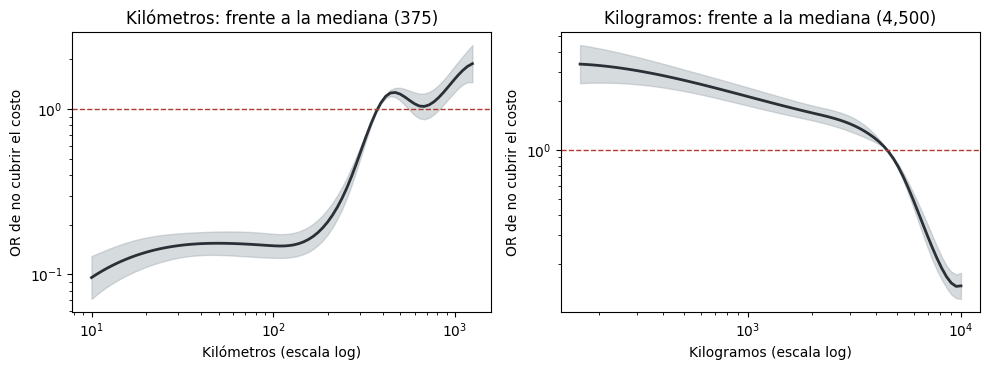

,km,OR_vs_mediana,IC_inf,IC_sup
0,50,0.15,0.13,0.18
1,100,0.15,0.13,0.18
2,200,0.21,0.18,0.25
3,300,0.54,0.49,0.58
4,400,1.13,1.11,1.15
5,450,1.26,1.20,1.32
6,500,1.23,1.13,1.34
7,600,1.07,0.92,1.26
8,800,1.15,0.97,1.37
9,1000,1.52,1.27,1.82


In [10]:
def curva_or(var, grilla):
    ref = {'KILOMETROS': d['KILOMETROS'].median(), 'KILOGRAMOS': d['KILOGRAMOS'].median(),
           'NATURALEZACARGA_G': 'Carga Normal', 'CAPITULO_G': cap_ref,
           'DEPARTAMENTOORIGEN_G': 'BOGOTA D. C.', 'DEPARTAMENTODESTINO_G': 'BOGOTA D. C.', 'NO_RENTABLE': 0}
    nd = pd.DataFrame([ref] * len(grilla)); nd[var] = grilla
    di = getattr(logit.model.data, 'model_spec', None) or logit.model.data.design_info   # statsmodels 0.15 / anteriores
    Xg = np.asarray(patsy.build_design_matrices([di], nd)[0])
    Xr = np.asarray(patsy.build_design_matrices([di], pd.DataFrame([ref]))[0])
    D = Xg - Xr
    eta = D @ logit.params.values
    se = np.sqrt(np.einsum('ij,jk,ik->i', D, logit.cov_params().values, D))
    return np.exp(eta), np.exp(eta - 1.96 * se), np.exp(eta + 1.96 * se)

g_km = np.geomspace(max(5, d['KILOMETROS'].quantile(0.01)), d['KILOMETROS'].quantile(0.99), 80)
g_kg = np.geomspace(max(50, d['KILOGRAMOS'].quantile(0.01)), d['KILOGRAMOS'].quantile(0.99), 80)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, var, g, lab in [(axes[0], 'KILOMETROS', g_km, 'Kilómetros'), (axes[1], 'KILOGRAMOS', g_kg, 'Kilogramos')]:
    o, lo, hi = curva_or(var, g)
    ax.fill_between(g, lo, hi, color='#9AA5AD', alpha=0.4); ax.plot(g, o, color='#2A3036', lw=2)
    ax.axhline(1, color='#B23A2E', ls='--', lw=1); ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel(f'{lab} (escala log)'); ax.set_ylabel('OR de no cubrir el costo')
    ax.set_title(f'{lab}: frente a la mediana ({d[var].median():,.0f})')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_or_curvas.png', dpi=200); plt.show()
tab_km = pd.DataFrame({'km': [50, 100, 200, 300, 400, 450, 500, 600, 800, 1000]})
tab_km['OR_vs_mediana'], tab_km['IC_inf'], tab_km['IC_sup'] = curva_or('KILOMETROS', tab_km['km'].values)
tab_km.to_csv(f'{OUT}/tabla_or_km.csv', index=False); tab_km.round(2)

## 6. Dónde se equivoca el modelo (prueba)

Para cerrar la lectura de errores se cruzan los errores de prueba con la distancia, la naturaleza de la carga y la cercanía al punto de equilibrio. Si muchos errores están en viajes pagados a menos de 10 % del costo, el problema es en parte de la etiqueta (que depende de la aproximación del costo por carrocería) y no solo del modelo.

In [11]:
ev = test[['KILOMETROS', 'NATURALEZACARGA']].copy()
ev['marca'] = (p0_te >= U_FINAL).astype(int); ev['no_rent'] = yneg_te
ev['error'] = np.where((ev.marca == 1) & (ev.no_rent == 0), 'Falso positivo', np.where((ev.marca == 0) & (ev.no_rent == 1), 'Falso negativo', 'Acierto'))
ev['cerca_equilibrio'] = aud_te['RAZON_PAGO_COSTO'].between(0.9, 1.1).values
ev['tramo_km'] = pd.cut(ev['KILOMETROS'], [0, 100, 250, 400, 600, 2000], labels=['≤100', '100-250', '250-400', '400-600', '>600'])
err_km = pd.crosstab(ev['tramo_km'], ev['error'], normalize='index').round(3)
err_eq = pd.crosstab(ev['cerca_equilibrio'], ev['error'], normalize='index').round(3)
err_km.to_csv(f'{OUT}/tabla_errores_km.csv'); err_eq.to_csv(f'{OUT}/tabla_errores_equilibrio.csv')
print('Viajes a ±10 % del costo en prueba:', f"{ev['cerca_equilibrio'].mean():.1%}")
print('Parte de los errores que está a ±10 % del costo:', f"{ev.loc[ev.error != 'Acierto', 'cerca_equilibrio'].mean():.1%}")
display(err_km); err_eq

Viajes a ±10 % del costo en prueba: 24.1%
Parte de los errores que está a ±10 % del costo: 42.5%


error,Acierto,Falso negativo,Falso positivo
tramo_km,,,
≤100,0.855,0.134,0.011
100-250,0.822,0.159,0.019
250-400,0.741,0.133,0.126
400-600,0.671,0.083,0.246
>600,0.656,0.154,0.189


error,Acierto,Falso negativo,Falso positivo
cerca_equilibrio,,,
False,0.805,0.086,0.109
True,0.546,0.256,0.198


## 7. Exportar el modelo para la aplicación

Se guarda el pipeline completo ya ajustado: imputación, logaritmo, splines, escalamiento, one-hot y la logística. La aplicación aplica exactamente las mismas transformaciones a lo que escribe el usuario, así que no hay diferencia entre cómo se entrenó y cómo se usa. El modelo desplegado es el mismo que se evaluó en la prueba. Junto al modelo se guardan el umbral, los rangos vistos en entrenamiento (para avisar si una entrada se sale de ellos) y las categorías válidas.

In [12]:
mercancias = (aud_tr.groupby('CAPITULO')['MERCANCIA'].agg(lambda s: s.value_counts().index[0]).str.slice(0, 70))
meta = {
    'modelo': MODELO, 'version_sklearn': sklearn.__version__, 'semilla': SEED,
    'hiperparametros': {'n_knots': int(best['pre__num__sp__n_knots']), 'C': float(best['clf__C'])},
    'umbral_costo': U_FINAL, 'alpha_base': ALPHA_BASE, 'umbral_youden': u_youden,
    'umbrales_por_alpha': {str(a): u for a, u in u_costo.items()},
    'auc_prueba': float(auc_te), 'auc_prueba_ic95': [float(ic[0]), float(ic[1])],
    'rangos': {v: [float(train[v].min()), float(train[v].quantile(0.01)), float(train[v].quantile(0.99)), float(train[v].max())] for v in NUM},
    'categorias': {c: train[c].value_counts().to_dict() for c in CAT},
    'capitulo_ejemplo_mercancia': mercancias.to_dict(),
    'km_por_ruta_mediana': {f'{o}|{de}': float(v) for (o, de), v in
                            train.groupby(['DEPARTAMENTOORIGEN', 'DEPARTAMENTODESTINO'])['KILOMETROS'].median().round(0).items()},
    'faltante_medio': float(faltante_tr[yneg_tr == 1].mean()), 'margen_medio': float(margen_tr[yneg_tr == 0].mean()),
}
joblib.dump(final, f'{APP}/modelo_final.joblib')
with open(f'{APP}/metadatos.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=1)
# Prueba de humo: el modelo guardado da lo mismo que el de memoria
re = joblib.load(f'{APP}/modelo_final.joblib')
assert np.allclose(re.predict_proba(X_test.head(50))[:, 0], p0_te[:50])
print('Guardado:', f'{APP}/modelo_final.joblib', '|', f'{APP}/metadatos.json')

Guardado: ../app/modelo_final.joblib | ../app/metadatos.json
